In [10]:

import glob
import pandas as pd
import numpy as np

# 1. Dataset Load
csv_files = glob.glob("*.csv")
df = pd.read_csv("cgpa.csv")

print("Loaded File: cgpa.csv")
print("\nTotal rows and columns in our dataset:")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

print("\nColumns in our dataset:")
print(df.columns.tolist())

# 2. Dataset Information
print("\n=== Dataset Info ===")
df.info()

# 3. Check Required Columns
required_columns = [
    "cgpa",
    "age",
    "gender",
    "daily_study_hours",
    "academic_pressure_score",
    "attendance_percentage",
    "assignment_marks_30",
    "midterm_marks_30",
    "final_marks_40",
    "total_marks_100",
    "Stress_Score",
    "anxiety_score",
    "depression_score",
    "daily_sleep_hours",
    "screen_time_hours",
    "financial_stress_score",
    "social_support_score",
    "physical_activity_hours"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("\nMissing required columns:", missing_columns)
else:
    print("\nAll required columns are available.")

# 4. Check Missing Values
print("\n=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Missing Values Percentage ===")
print((df.isnull().sum() / len(df) * 100).round(2))

# 5. Check Duplicate Rows
print("\n=== Duplicate Rows ===")
print(f"Duplicate values: {df.duplicated().sum()}")

df = df.drop_duplicates().copy()

print(f"Rows after removing duplicates: {df.shape[0]}")

# 6. Check CGPA Target Column
if "cgpa" in df.columns:
    df["cgpa"] = pd.to_numeric(df["cgpa"], errors="coerce")

    print("\n=== CGPA Summary ===")
    print(df["cgpa"].describe())

    print("\nMissing or invalid CGPA values:")
    print(df["cgpa"].isnull().sum())

    print("\nCGPA values outside the expected 0-4 range:")
    print(
        ((df["cgpa"] < 0) | (df["cgpa"] > 4)).sum()
    )

    print("\n=== Sample CGPA Records ===")
    print(df[["cgpa"]].head(10))

else:
    raise ValueError("ERROR: 'cgpa' target column not found.")

# 7. Analyze Academic and Lifestyle Features
# Experiment B: Individual marks included; total marks excluded
analysis_features = [
    "daily_study_hours",
    "academic_pressure_score",
    "attendance_percentage",
    "assignment_marks_30",
    "midterm_marks_30",
    "final_marks_40",
    "Stress_Score",
    "anxiety_score",
    "depression_score",
    "daily_sleep_hours",
    "screen_time_hours",
    "financial_stress_score",
    "social_support_score",
    "physical_activity_hours"
]

available_features = [
    col for col in analysis_features
    if col in df.columns
]

for col in available_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\n=== Average Features by CGPA Range ===")

df["CGPA_Range"] = pd.cut(
    df["cgpa"],
    bins=[-0.01, 1.0, 2.0, 3.0, 4.0],
    labels=["0-1", "1-2", "2-3", "3-4"]
)

print(
    df.groupby("CGPA_Range", observed=False)[available_features]
    .mean()
    .round(2)
)

df.drop(columns=["CGPA_Range"], inplace=True)

# 8. Display First Five Rows
print("\n=== First Five Rows ===")
print(df.head())


Loaded File: cgpa.csv

Total rows and columns in our dataset:
Total Rows: 150000
Total Columns: 32

Columns in our dataset:
['student_id', 'age', 'gender', 'Burnout_Score', 'course_id', 'academic_id', 'environment_id', 'wellness_id', 'course', 'Stress_Score', 'anxiety_score', 'depression_score', 'year', 'daily_study_hours', 'academic_pressure_score', 'attendance_percentage', 'cgpa', 'screen_time_hours', 'financial_stress_score', 'Internet_Quality_Score', 'daily_sleep_hours', 'social_support_score', 'physical_activity_hours', 'Sleep_Quality_Score', 'stress_level', 'sleep_quality', 'internet_quality', 'burnout_level', 'assignment_marks_30', 'midterm_marks_30', 'final_marks_40', 'total_marks_100']

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 32 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   student_id               150000 non-null  int64  
 1   age 

eda

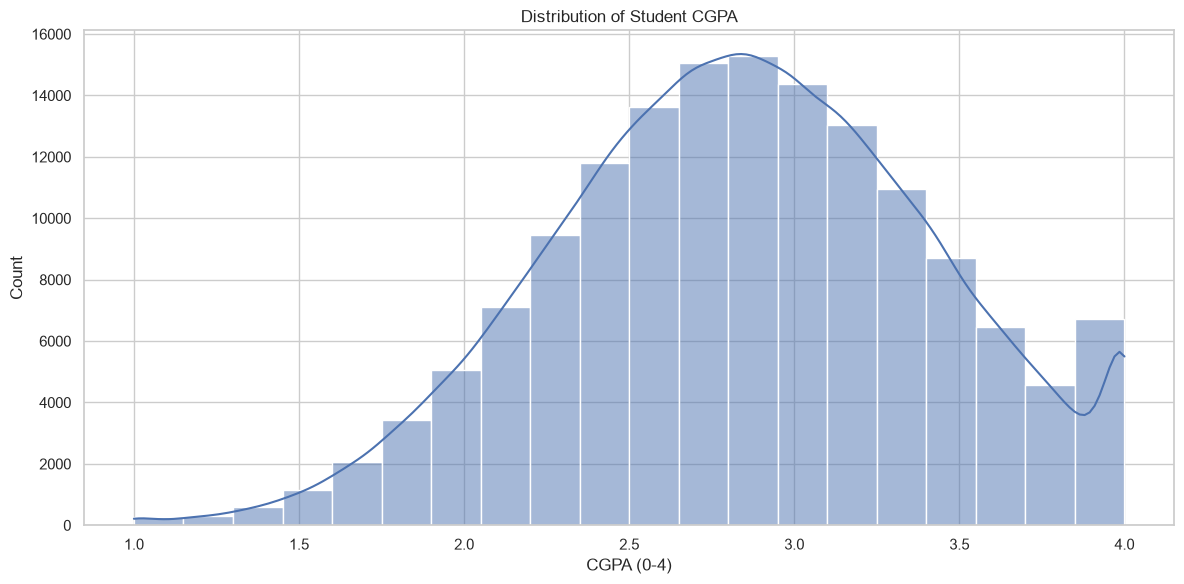

=== CGPA Summary ===
count    150000.00
mean          2.84
std           0.57
min           1.00
25%           2.45
50%           2.85
75%           3.24
max           4.00
Name: cgpa, dtype: float64

Input Features: ['age', 'gender', 'Burnout_Score', 'course', 'Stress_Score', 'anxiety_score', 'depression_score', 'year', 'daily_study_hours', 'academic_pressure_score', 'attendance_percentage', 'screen_time_hours', 'financial_stress_score', 'Internet_Quality_Score', 'daily_sleep_hours', 'social_support_score', 'physical_activity_hours', 'Sleep_Quality_Score', 'stress_level', 'sleep_quality', 'internet_quality', 'burnout_level', 'assignment_marks_30', 'midterm_marks_30', 'final_marks_40']
Number of Features: 25
Target: cgpa


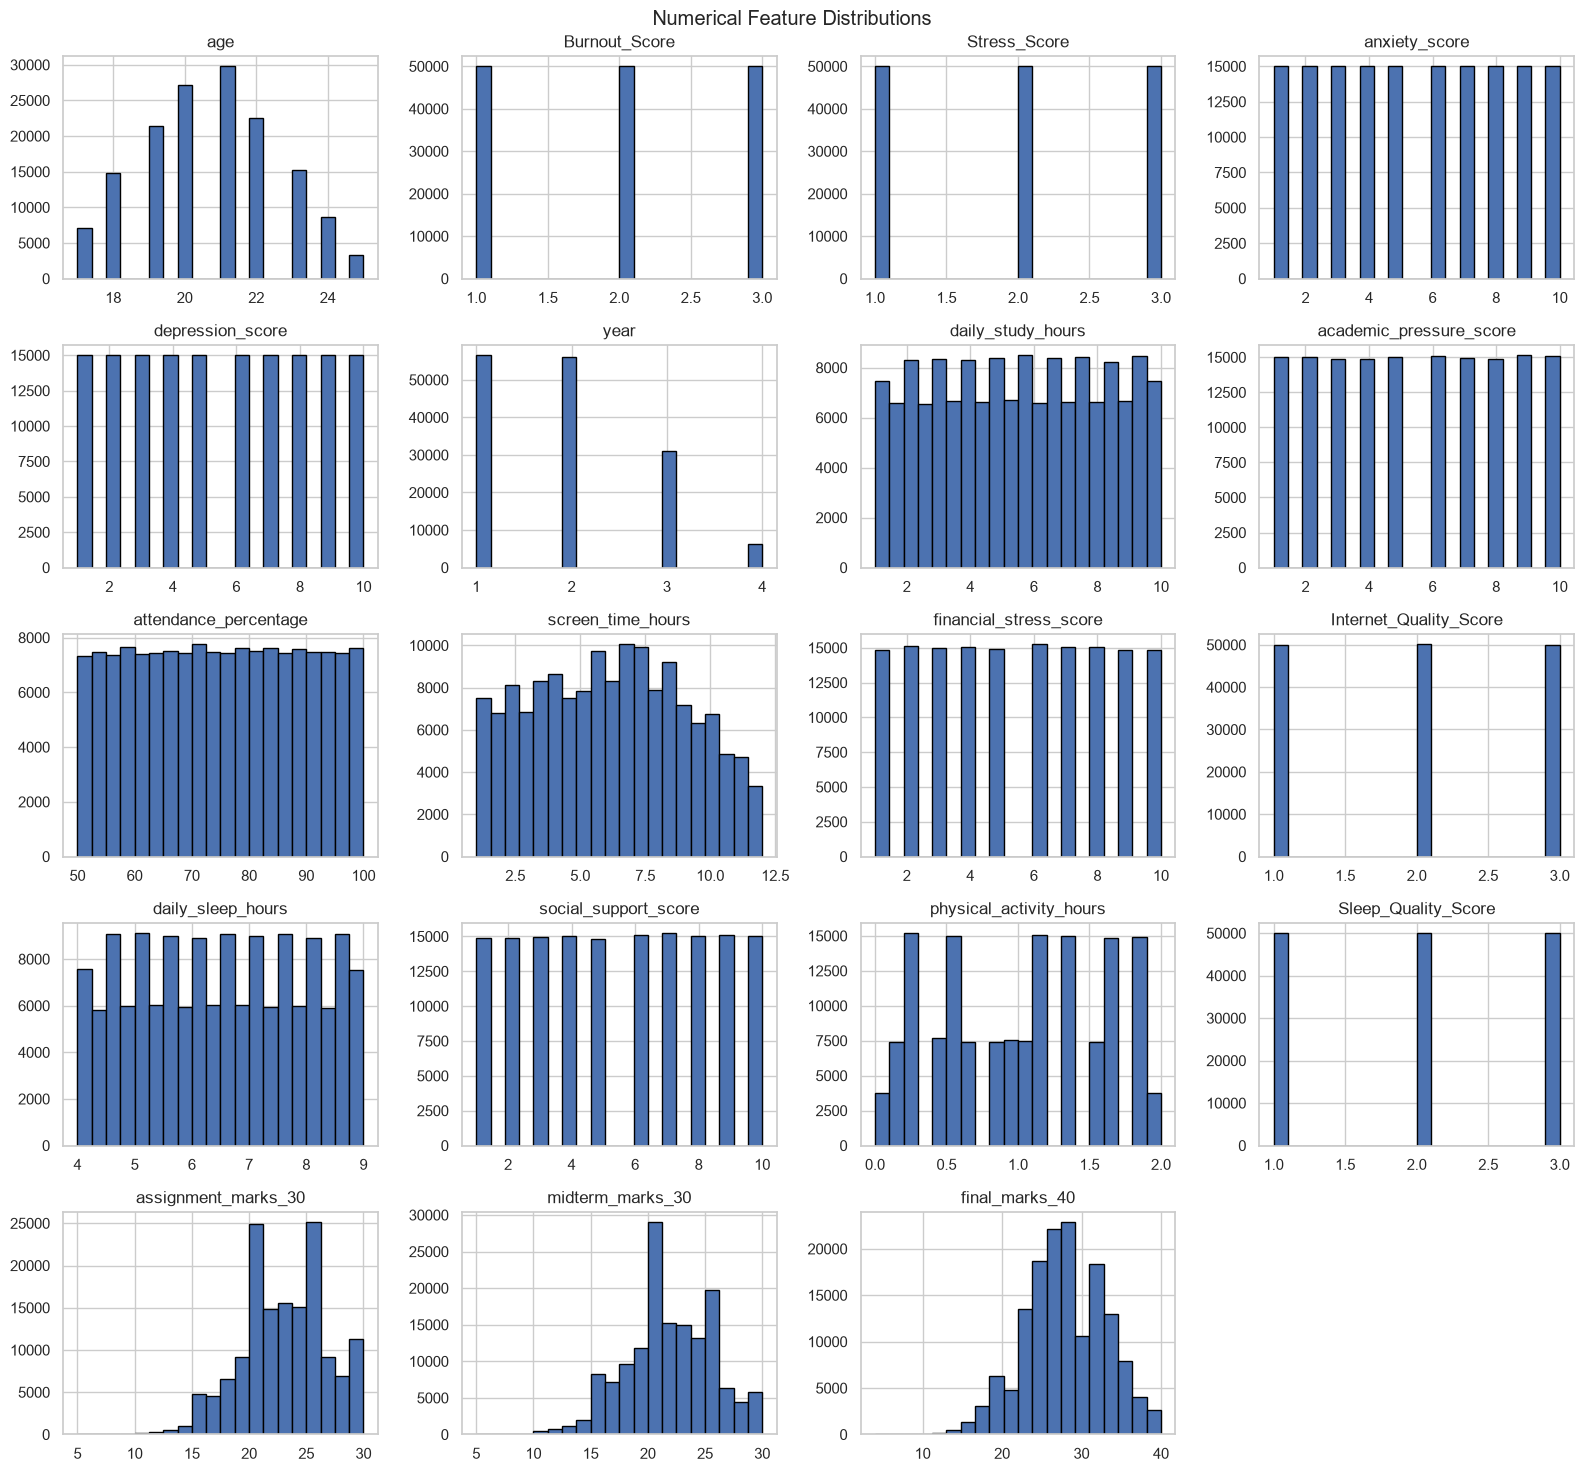

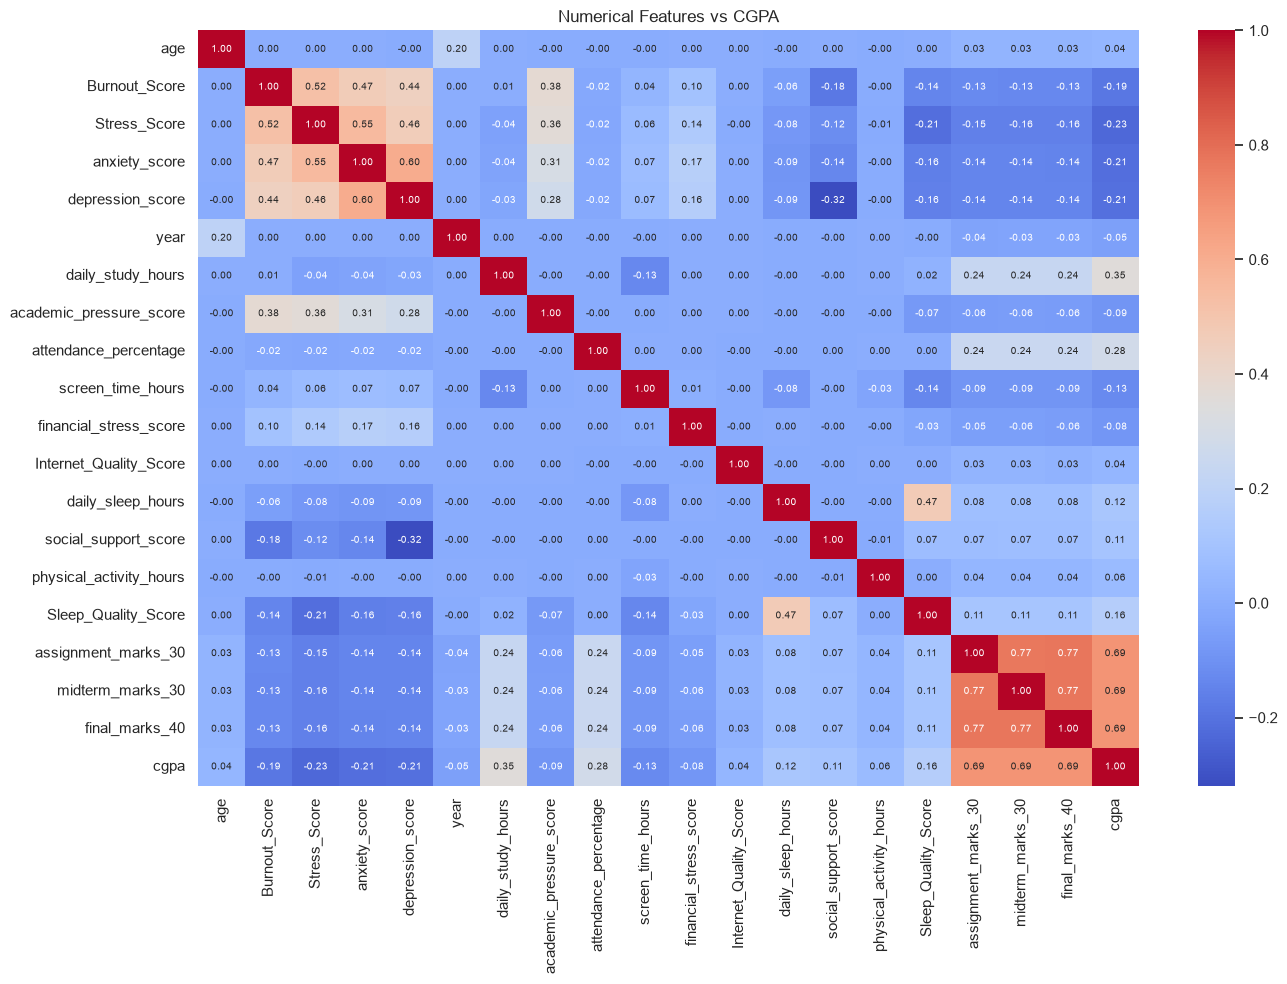

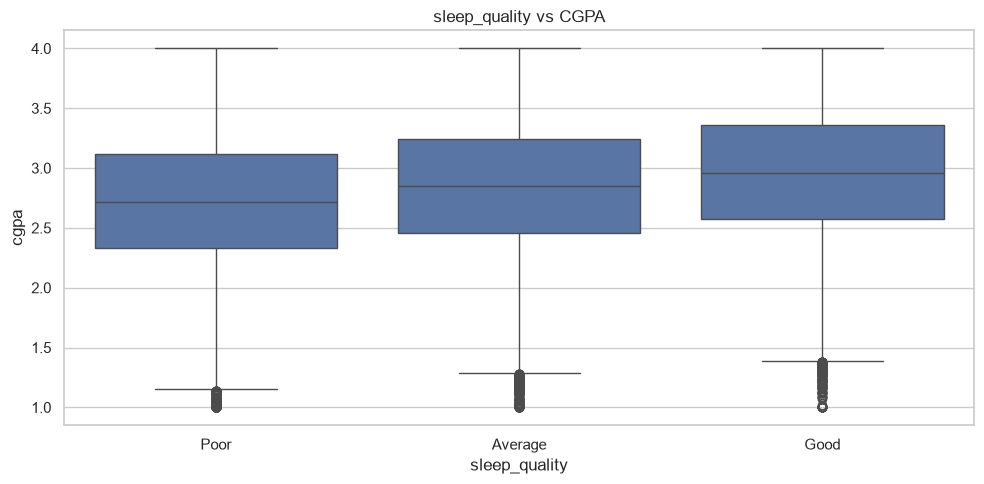

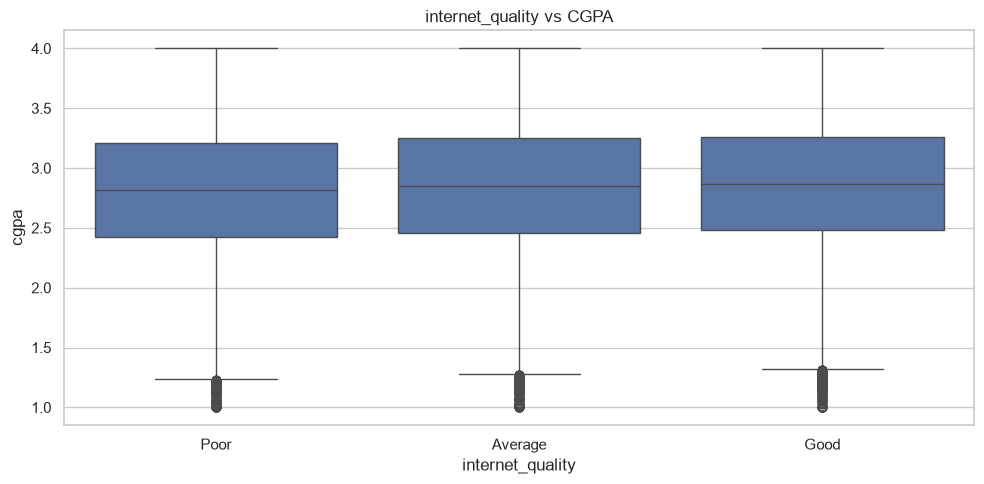

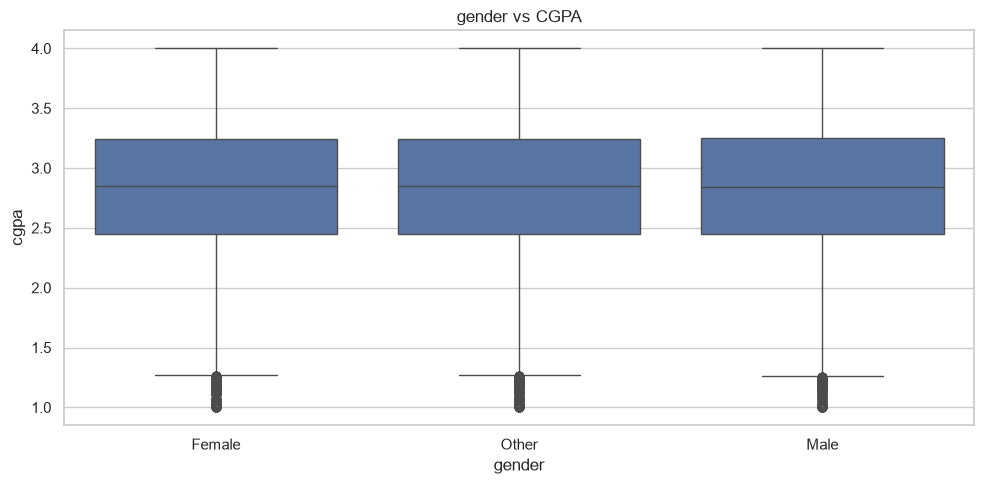

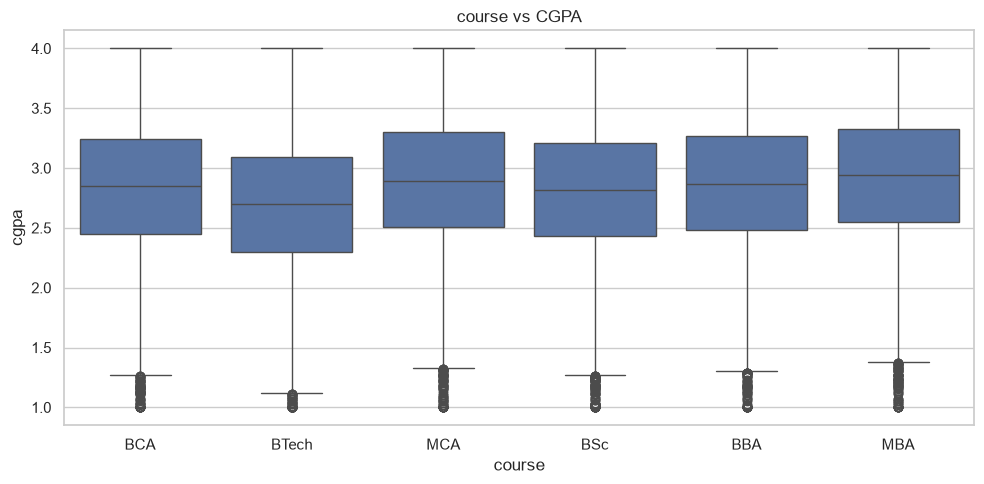

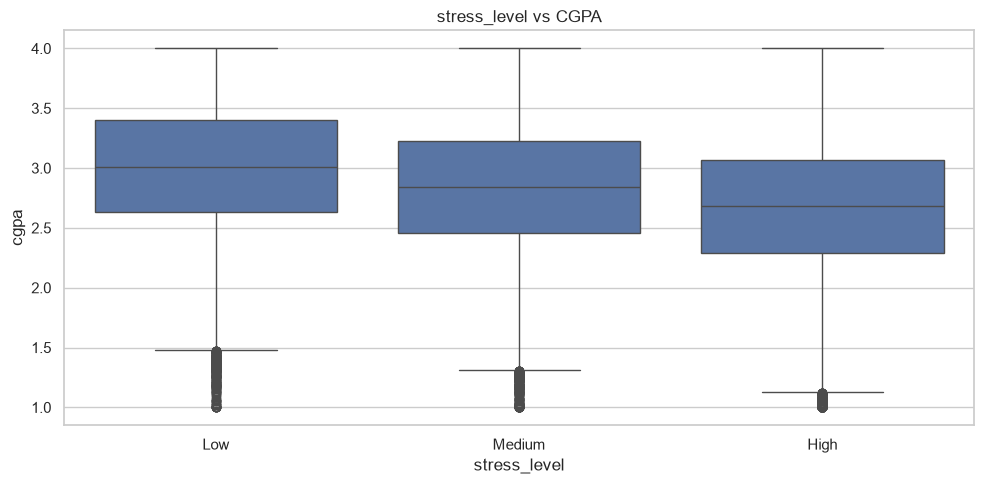

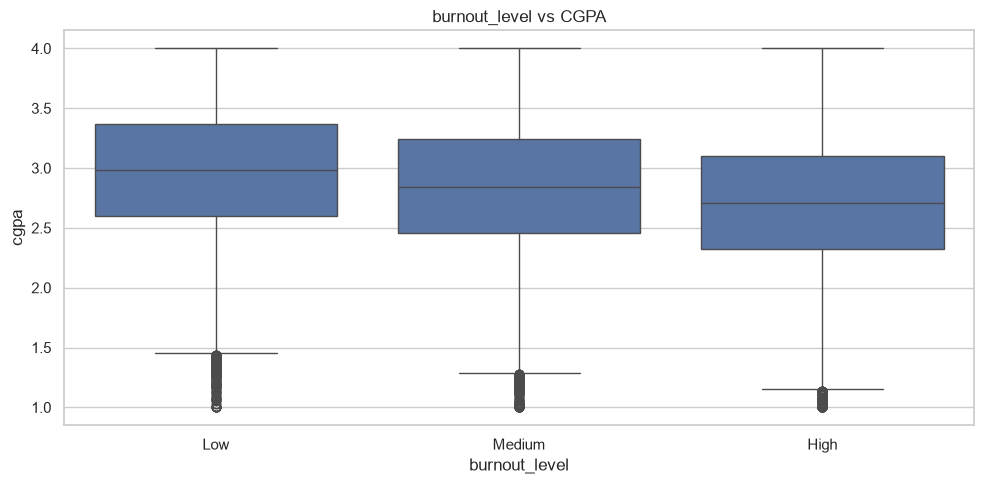

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Clean target
target_col = "cgpa"

if target_col not in df.columns:
    raise ValueError(f"'{target_col}' column not found.")

clean_df = df.copy()
clean_df[target_col] = pd.to_numeric(clean_df[target_col], errors="coerce")
clean_df = clean_df.dropna(subset=[target_col])
clean_df = clean_df[clean_df[target_col].between(0, 4)].copy()

# 2. CGPA distribution and summary
sns.histplot(data=clean_df, x=target_col, bins=20, kde=True)
plt.title("Distribution of Student CGPA")
plt.xlabel("CGPA (0-4)")
plt.tight_layout()
plt.show()

print("=== CGPA Summary ===")
print(clean_df[target_col].describe().round(2))

# 3. Separate features and target
drop_cols = [
    target_col, "total_marks_100", "student_id", "course_id",
    "academic_id", "environment_id", "wellness_id"
]

X = clean_df.drop(columns=drop_cols, errors="ignore")
y = clean_df[target_col]

num_cols = X.select_dtypes(include="number").columns.tolist()

print("\nInput Features:", X.columns.tolist())
print("Number of Features:", X.shape[1])
print("Target:", target_col)

# 4. Numerical feature histograms
if num_cols:
    X[num_cols].hist(
        bins=20,
        figsize=(16, max(5, 3 * int(__import__("math").ceil(len(num_cols) / 4)))),
        layout=(int(np.ceil(len(num_cols) / 4)), 4),
        edgecolor="black"
    )
    plt.suptitle("Numerical Feature Distributions")
    plt.tight_layout()
    plt.show()

# 5. Correlation heatmap (total marks excluded)
corr_df = clean_df[num_cols + [target_col]]

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_df.corr(numeric_only=True),
    annot=True, fmt=".2f", cmap="coolwarm",
    annot_kws={"size": 7}
)
plt.title("Numerical Features vs CGPA")
plt.tight_layout()
plt.show()

# 6. Categorical features vs CGPA
cat_orders = {
    "sleep_quality": ["Poor", "Average", "Good"],
    "internet_quality": ["Poor", "Average", "Good"],
    "stress_level": ["Low", "Medium", "High"],
    "burnout_level": ["Low", "Medium", "High"]
}

for col in ["sleep_quality", "internet_quality", "gender",
            "course", "stress_level", "burnout_level"]:
    if col in clean_df.columns:
        plt.figure(figsize=(10, 5))
        sns.boxplot(
            data=clean_df, x=col, y=target_col,
            order=cat_orders.get(col)
        )
        plt.title(f"{col} vs CGPA")
        plt.tight_layout()
        plt.show()


model training

In [17]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Target and columns to drop
target_col = "cgpa"

drop_cols = [
    target_col,
    "student_id",
    "course_id",
    "academic_id",
    "environment_id",
    "wellness_id",
    "total_marks_100"
]

# Check target column
if target_col not in df.columns:
    raise ValueError(f"Target column '{target_col}' not found in dataset.")

# 2. Clean target
clean_df = df.copy()

clean_df[target_col] = pd.to_numeric(
    clean_df[target_col], errors="coerce"
)

clean_df = clean_df.dropna(subset=[target_col]).copy()
clean_df = clean_df[
    clean_df[target_col].between(0, 4)
].copy()

# 3. Separate features and target
# Individual marks AND all other relevant columns are included
X = clean_df.drop(columns=drop_cols, errors="ignore")
y = clean_df[target_col].astype(float)

# 4. Handle categorical features
categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_cols:
    X[col] = X[col].fillna("Unknown").astype(str)

# 5. Encode categorical features
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

# Ensure numeric values
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# 7. Fill missing values using training medians
train_median = X_train.median().fillna(0)
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)

# 8. Scale features
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# 9. Display results
print("CGPA Prediction Preprocessing Complete")
print("Experiment B: Individual marks + other features")
print("Prediction Type: Regression")
print("Input Features:", X.shape[1])
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nAll Input Features:")
print(X.columns.tolist())

print("\n=== Feature Verification ===")

for col in [
    "assignment_marks_30",
    "midterm_marks_30",
    "final_marks_40",
    "daily_study_hours",
    "attendance_percentage",
    "daily_sleep_hours",
    "Stress_Score",
    "anxiety_score",
    "depression_score",
    "physical_activity_hours"
]:
    print(f"{col}: {'Included' if col in X.columns else 'NOT FOUND'}")

print("\ntotal_marks_100:",
      "Excluded" if "total_marks_100" not in X.columns else "ERROR: Included")

print("\nTarget Column:", target_col)

print("\nTraining CGPA Statistics:")
print(y_train.describe().round(2))

print("\nTesting CGPA Statistics:")
print(y_test.describe().round(2))


CGPA Prediction Preprocessing Complete
Experiment B: Individual marks + other features
Prediction Type: Regression
Input Features: 40
Training Samples: 105000
Testing Samples: 45000

All Input Features:
['age', 'Burnout_Score', 'Stress_Score', 'anxiety_score', 'depression_score', 'year', 'daily_study_hours', 'academic_pressure_score', 'attendance_percentage', 'screen_time_hours', 'financial_stress_score', 'Internet_Quality_Score', 'daily_sleep_hours', 'social_support_score', 'physical_activity_hours', 'Sleep_Quality_Score', 'assignment_marks_30', 'midterm_marks_30', 'final_marks_40', 'gender_Female', 'gender_Male', 'gender_Other', 'course_BBA', 'course_BCA', 'course_BSc', 'course_BTech', 'course_MBA', 'course_MCA', 'stress_level_High', 'stress_level_Low', 'stress_level_Medium', 'sleep_quality_Average', 'sleep_quality_Good', 'sleep_quality_Poor', 'internet_quality_Average', 'internet_quality_Good', 'internet_quality_Poor', 'burnout_level_High', 'burnout_level_Low', 'burnout_level_Medium

importance feature


=== CGPA PREDICTION FEATURE IMPORTANCES ===
                 Feature  Importance
          final_marks_40    0.406608
     assignment_marks_30    0.227386
        midterm_marks_30    0.213746
       daily_study_hours    0.055669
   attendance_percentage    0.024151
                    year    0.008883
       daily_sleep_hours    0.007329
        depression_score    0.007298
       screen_time_hours    0.007201
           anxiety_score    0.007148
            Stress_Score    0.005173
 physical_activity_hours    0.003470
    social_support_score    0.002839
       stress_level_High    0.002498
            course_BTech    0.002395
  financial_stress_score    0.002319
        stress_level_Low    0.002289
                     age    0.001809
           Burnout_Score    0.001790
 academic_pressure_score    0.001737
     Sleep_Quality_Score    0.001294
      burnout_level_High    0.000916
       burnout_level_Low    0.000841
      sleep_quality_Poor    0.000709
      sleep_quality_Good    0.0

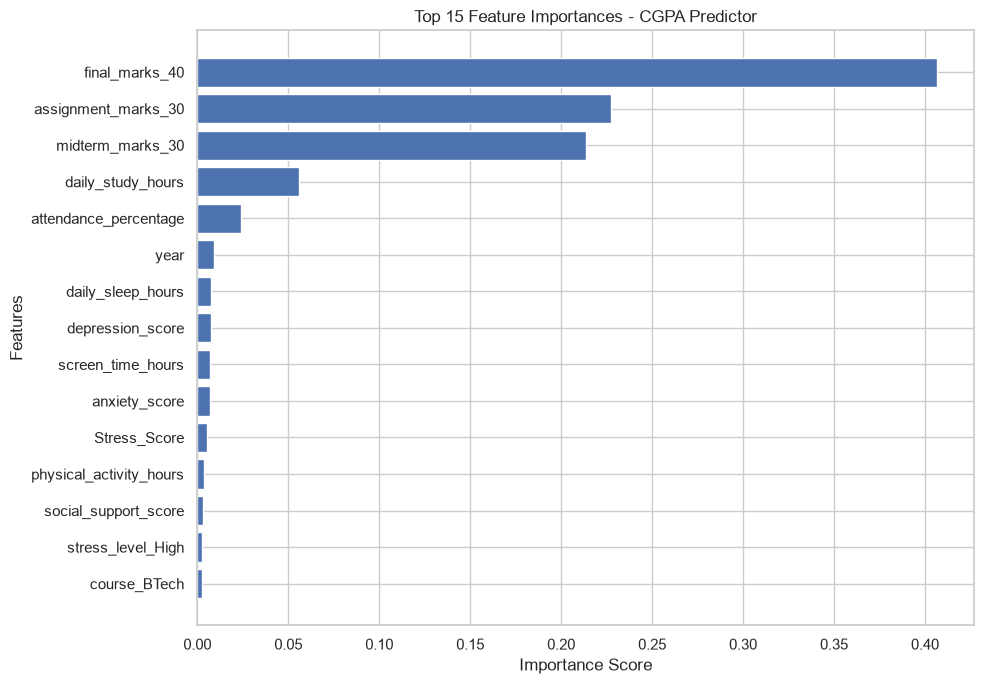

In [18]:

from sklearn.ensemble import RandomForestRegressor

# 1. Train the Random Forest Regression model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 2. Extract feature importances
importances = model.feature_importances_

# 3. Create a DataFrame of feature importances
feat_importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances
})

# 4. Sort features by importance
feat_importances = feat_importances.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# 5. Display feature importances
print("=== CGPA PREDICTION FEATURE IMPORTANCES ===")
print(feat_importances.to_string(index=False))

# 6. Plot top 15 feature importances
top_features = (
    feat_importances.head(15)
    .sort_values(by="Importance", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances - CGPA Predictor")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


Training Baseline Dummy...
Training Linear Regression...
Training Ridge Regression...
Training KNN...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...

Manual weightage total: 100.0 %

===== CGPA MODEL COMPARISON =====
                Model  Train MAE  Test MAE   RMSE  R2 Score  Overfitting Gap
    Linear Regression     0.2807    0.2819 0.3531    0.6225           0.0012
     Ridge Regression     0.2807    0.2819 0.3531    0.6225           0.0012
    Gradient Boosting     0.2792    0.2825 0.3534    0.6218           0.0034
        Random Forest     0.2404    0.2836 0.3549    0.6187           0.0432
Manual Weighted Model     0.2898    0.2911 0.3644    0.5981           0.0013
        Decision Tree     0.2931    0.2998 0.3752    0.5737           0.0067
                  KNN     0.2736    0.3345 0.4180    0.4711           0.0609
       Baseline Dummy     0.4620    0.4645 0.5748   -0.0001           0.0025

Best original model: Linear Regression
Manual Weighted

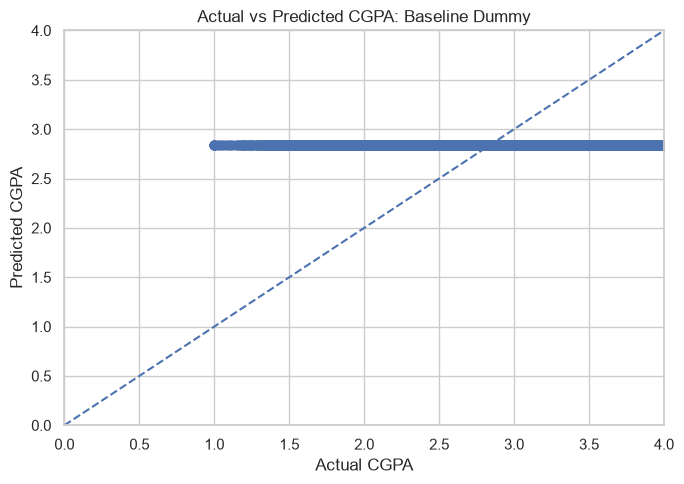

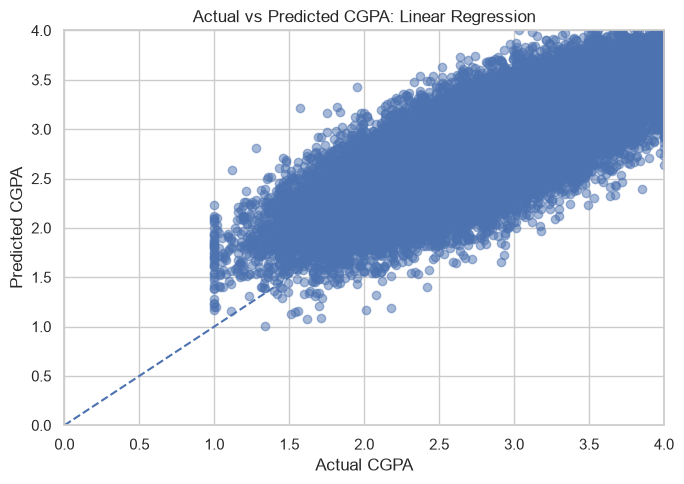

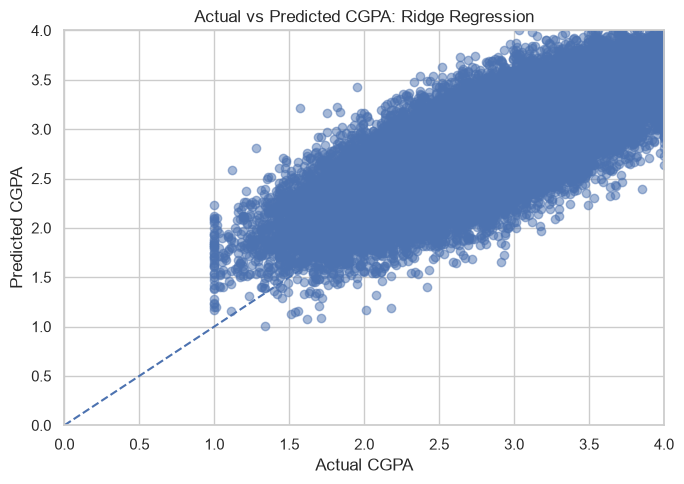

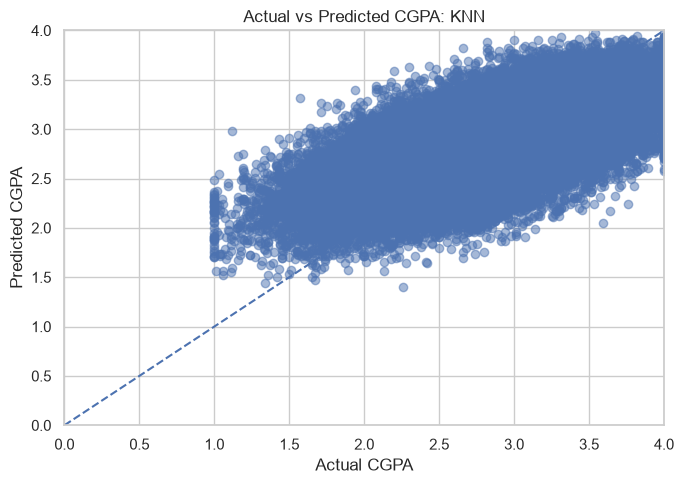

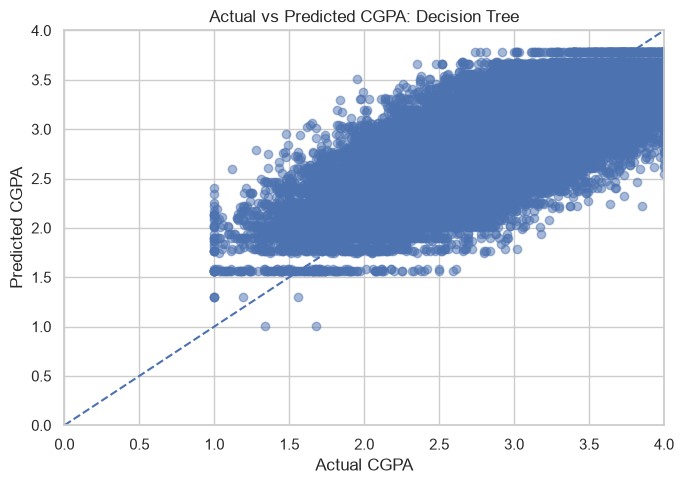

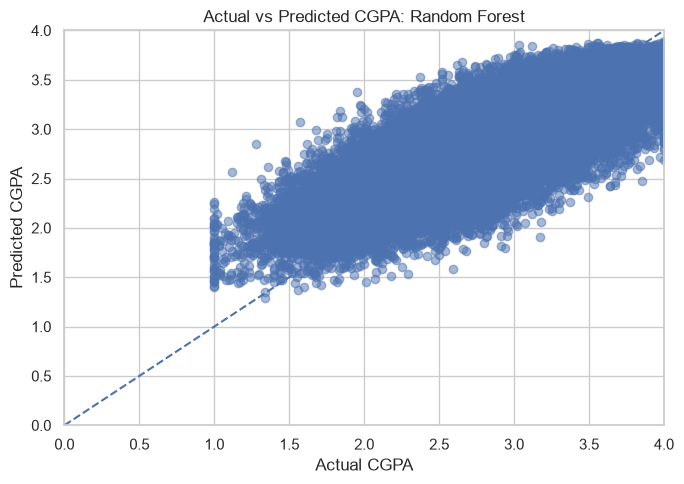

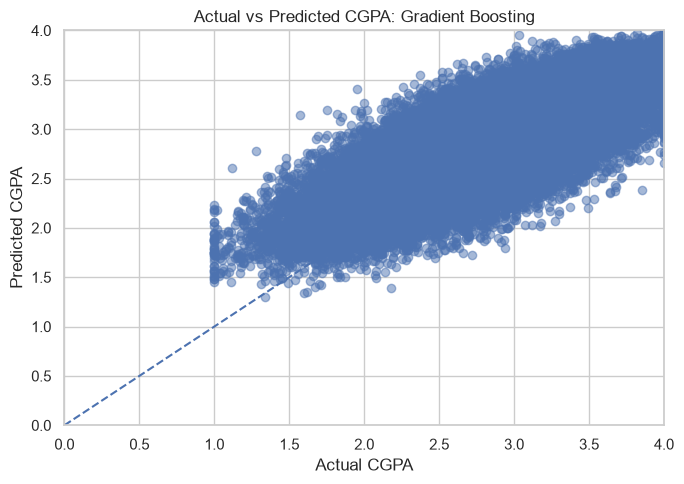

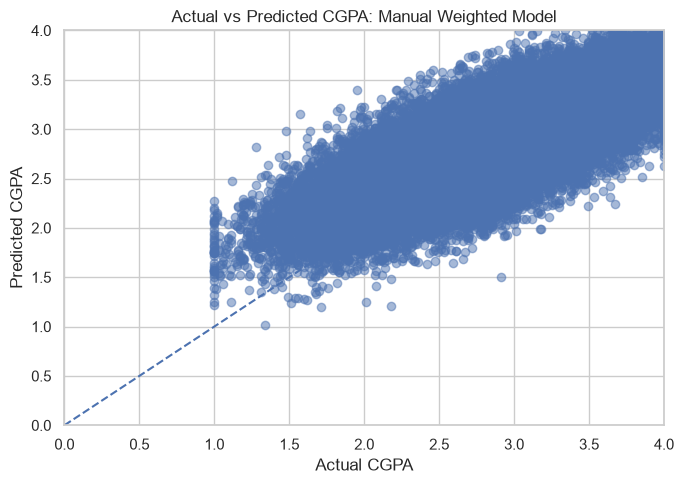


===== MANUAL WEIGHTED MODEL: SAMPLE RESULTS =====
 Actual CGPA  Predicted CGPA
        3.21            2.86
        2.43            2.52
        3.62            3.25
        3.06            3.14
        2.52            3.07
        2.12            2.18
        2.82            2.86
        3.24            3.38
        3.11            3.36
        1.64            2.02


In [19]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================
# 1. ORIGINAL MODELS
# ==========================================

models = {
    "Baseline Dummy": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "KNN": KNeighborsRegressor(n_neighbors=5, n_jobs=-1),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []
trained_models = {}
predictions = {}

# ==========================================
# 2. TRAIN ORIGINAL MODELS
# ==========================================

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred),
        "Overfitting Gap": (
            mean_absolute_error(y_test, y_pred)
            - mean_absolute_error(y_train, train_pred)
        )
    })

    trained_models[name] = model
    predictions[name] = np.clip(y_pred, 0, 4)

# ==========================================
# 3. MANUAL WEIGHTAGE
# ==========================================

main_weights = {
    "final_marks_40": 28,
    "midterm_marks_30": 22,
    "assignment_marks_30": 13,
    "daily_study_hours": 15,
    "attendance_percentage": 6
}

stress_features = [
    "Stress_Score",
    "anxiety_score",
    "depression_score",
    "financial_stress_score"
]

stress_weight = 10
remaining_weight = 6

# Map encoded columns back to their original columns
excluded = {
    "cgpa", "student_id", "course_id", "academic_id",
    "environment_id", "wellness_id", "total_marks_100"
}

raw_features = [
    col for col in clean_df.columns
    if col not in excluded
]

encoded_to_raw = {}

for col in X_train.columns:
    matches = [
        raw for raw in raw_features
        if col == raw or col.startswith(raw + "_")
    ]

    if matches:
        encoded_to_raw[col] = max(matches, key=len)
    else:
        encoded_to_raw[col] = col

raw_to_encoded = {}

for encoded, raw in encoded_to_raw.items():
    raw_to_encoded.setdefault(raw, []).append(encoded)

# Verify required features exist
required = list(main_weights) + stress_features
missing = [col for col in required if col not in raw_to_encoded]

if missing:
    raise ValueError(
        f"Weightage features missing from X_train: {missing}"
    )

remaining_features = [
    raw for raw in raw_to_encoded
    if raw not in main_weights and raw not in stress_features
]

if not remaining_features:
    raise ValueError("No remaining features found for the 6% group.")

# Distribute the group weights across encoded columns
feature_weights = {}

for raw, weight in main_weights.items():
    for col in raw_to_encoded[raw]:
        feature_weights[col] = weight / len(raw_to_encoded[raw])

for raw in stress_features:
    weight = stress_weight / len(stress_features)
    for col in raw_to_encoded[raw]:
        feature_weights[col] = weight / len(raw_to_encoded[raw])

remaining_each = remaining_weight / len(remaining_features)

for raw in remaining_features:
    for col in raw_to_encoded[raw]:
        feature_weights[col] = (
            remaining_each / len(raw_to_encoded[raw])
        )

weights = pd.Series(feature_weights).reindex(
    X_train.columns, fill_value=0
) / 100

print("\nManual weightage total:",
      round(weights.sum() * 100, 2), "%")

# ==========================================
# 4. NORMALIZE USING TRAINING DATA ONLY
# ==========================================

train_min = X_train.min()
train_max = X_train.max()
train_range = (train_max - train_min).replace(0, 1)

Xtr = ((X_train - train_min) / train_range).clip(0, 1).fillna(0)
Xte = ((X_test - train_min) / train_range).clip(0, 1).fillna(0)

# Reverse features that have negative correlation with CGPA.
# Correlations are calculated using training data only.
correlations = Xtr.corrwith(y_train).fillna(0)

for col in Xtr.columns:
    if correlations[col] < 0:
        Xtr[col] = 1 - Xtr[col]
        Xte[col] = 1 - Xte[col]

# ==========================================
# 5. CREATE WEIGHTED SCORE
# ==========================================

train_score = Xtr.mul(weights, axis=1).sum(axis=1)
test_score = Xte.mul(weights, axis=1).sum(axis=1)

# Learn how the weighted score relates to actual CGPA
weighted_model = LinearRegression()
weighted_model.fit(train_score.to_frame("weighted_score"), y_train)

weighted_train_pred = np.clip(
    weighted_model.predict(train_score.to_frame("weighted_score")),
    0, 4
)

weighted_test_pred = np.clip(
    weighted_model.predict(test_score.to_frame("weighted_score")),
    0, 4
)

predictions["Manual Weighted Model"] = weighted_test_pred

results.append({
    "Model": "Manual Weighted Model",
    "Train MAE": mean_absolute_error(y_train, weighted_train_pred),
    "Test MAE": mean_absolute_error(y_test, weighted_test_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, weighted_test_pred)),
    "R2 Score": r2_score(y_test, weighted_test_pred),
    "Overfitting Gap": (
        mean_absolute_error(y_test, weighted_test_pred)
        - mean_absolute_error(y_train, weighted_train_pred)
    )
})

# ==========================================
# 6. COMPARE ALL MODELS
# ==========================================

results_df = (
    pd.DataFrame(results)
    .sort_values("Test MAE")
    .reset_index(drop=True)
)

print("\n===== CGPA MODEL COMPARISON =====")
print(results_df.round(4).to_string(index=False))

# Best among the original trained models.
# Manual Weighted Model uses a separate prediction process.
original_results = results_df[
    results_df["Model"] != "Manual Weighted Model"
]

best_model_name = original_results[
    original_results["Model"] != "Baseline Dummy"
].iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("\nBest original model:", best_model_name)
print("Manual Weighted Model Test MAE:",
      round(
          results_df.loc[
              results_df["Model"] == "Manual Weighted Model",
              "Test MAE"
          ].iloc[0], 4
      ))

# ==========================================
# 7. ACTUAL VS PREDICTED PLOTS
# ==========================================

for model_name, y_pred in predictions.items():
    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred, alpha=0.5)

    plt.plot([0, 4], [0, 4], linestyle="--")
    plt.xlim(0, 4)
    plt.ylim(0, 4)

    plt.title(f"Actual vs Predicted CGPA: {model_name}")
    plt.xlabel("Actual CGPA")
    plt.ylabel("Predicted CGPA")
    plt.tight_layout()
    plt.show()

print("\n===== MANUAL WEIGHTED MODEL: SAMPLE RESULTS =====")
print(pd.DataFrame({
    "Actual CGPA": y_test.iloc[:10].to_numpy(),
    "Predicted CGPA": np.round(weighted_test_pred[:10], 2)
}).to_string(index=False))


=== CGPA PREDICTION FEATURE IMPORTANCES ===
                 Feature  Importance
          final_marks_40    0.406608
     assignment_marks_30    0.227386
        midterm_marks_30    0.213746
       daily_study_hours    0.055669
   attendance_percentage    0.024151
                    year    0.008883
       daily_sleep_hours    0.007329
        depression_score    0.007298
       screen_time_hours    0.007201
           anxiety_score    0.007148
            Stress_Score    0.005173
 physical_activity_hours    0.003470
    social_support_score    0.002839
       stress_level_High    0.002498
            course_BTech    0.002395
  financial_stress_score    0.002319
        stress_level_Low    0.002289
                     age    0.001809
           Burnout_Score    0.001790
 academic_pressure_score    0.001737
     Sleep_Quality_Score    0.001294
      burnout_level_High    0.000916
       burnout_level_Low    0.000841
      sleep_quality_Poor    0.000709
      sleep_quality_Good    0.0

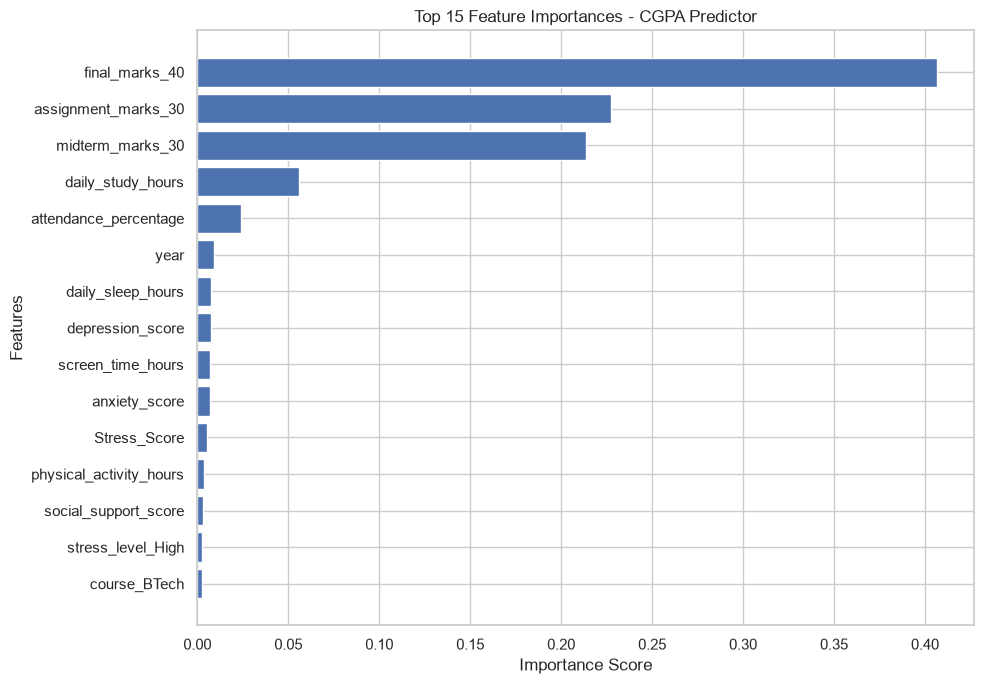

In [20]:

from sklearn.ensemble import RandomForestRegressor

# 1. Train the Random Forest Regression model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 2. Extract feature importances
importances = model.feature_importances_

# 3. Create a DataFrame of feature importances
feat_importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances
})

# 4. Sort features by importance
feat_importances = feat_importances.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# 5. Display feature importances
print("=== CGPA PREDICTION FEATURE IMPORTANCES ===")
print(feat_importances.to_string(index=False))

# 6. Plot top 15 feature importances
top_features = (
    feat_importances.head(15)
    .sort_values(by="Importance", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances - CGPA Predictor")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [15]:

# ==========================================
# LIVE CGPA PREDICTION FROM USER INPUT
# ==========================================

def ask_number(prompt, low, high, as_int=False):
    while True:
        try:
            value = float(input(f"{prompt} ({low}-{high}): "))

            if low <= value <= high:
                return int(value) if as_int else value

            print(f"Value {low} se {high} ke darmiyan honi chahiye.")

        except ValueError:
            print("Sirf number likhein.")


def ask_choice(prompt, options):
    while True:
        value = input(f"{prompt} {options}: ").strip()

        for opt in options:
            if value.lower() == opt.lower():
                return opt

        print("Diye gaye options mein se likhein.")


def live_cgpa_prediction():

    print("\n===================================")
    print("       STUDENT CGPA PREDICTOR")
    print("===================================")

    # 1. Student input
    age = ask_number("Age", 18, 26, as_int=True)
    gender = ask_choice("Gender", ["Female", "Male", "Other"])
    course = input("Course name: ").strip()
    year = ask_number("Year of study", 1, 4, as_int=True)

    stress_score = ask_number("Stress score", 1, 10)
    anxiety = ask_number("Anxiety score", 1, 10)
    depression = ask_number("Depression score", 1, 10)

    study_hours = ask_number("Daily study hours", 0, 24)
    academic_pressure = ask_number("Academic pressure score", 1, 10)
    attendance = ask_number("Attendance percentage", 0, 100)

    screen_hours = ask_number("Daily screen time hours", 0, 24)
    financial_stress = ask_number("Financial stress score", 1, 10)
    internet_quality_score = ask_number("Internet quality score", 1, 10)
    sleep_hours = ask_number("Daily sleep hours", 0, 24)
    social_support = ask_number("Social support score", 1, 10)
    activity_hours = ask_number("Physical activity hours", 0, 24)
    sleep_quality_score = ask_number("Sleep quality score", 1, 10)

    sleep_quality = ask_choice(
        "Sleep quality", ["Poor", "Average", "Good"]
    )
    internet_quality = ask_choice(
        "Internet quality", ["Poor", "Average", "Good"]
    )

    burnout_score = ask_number("Burnout score", 1, 3, as_int=True)
    burnout_level = ask_choice(
        "Burnout level", ["Low", "Medium", "High"]
    )
    stress_level = ask_choice(
        "Stress level", ["Low", "Medium", "High"]
    )

    # Individual marks are included in the model
    assignment_marks = ask_number("Assignment marks (out of 30)", 0, 30)
    midterm_marks = ask_number("Midterm marks (out of 30)", 0, 30)
    final_marks = ask_number("Final exam marks (out of 40)", 0, 40)

    # Total is calculated for display only; it is NOT a model feature
    total_marks = assignment_marks + midterm_marks + final_marks

    # 2. Raw input DataFrame
    user_data = pd.DataFrame([{
        "age": age,
        "gender": gender,
        "course": course,
        "Burnout_Score": burnout_score,
        "Stress_Score": stress_score,
        "anxiety_score": anxiety,
        "depression_score": depression,
        "year": year,
        "daily_study_hours": study_hours,
        "academic_pressure_score": academic_pressure,
        "attendance_percentage": attendance,
        "screen_time_hours": screen_hours,
        "financial_stress_score": financial_stress,
        "Internet_Quality_Score": internet_quality_score,
        "daily_sleep_hours": sleep_hours,
        "social_support_score": social_support,
        "physical_activity_hours": activity_hours,
        "Sleep_Quality_Score": sleep_quality_score,
        "stress_level": stress_level,
        "sleep_quality": sleep_quality,
        "internet_quality": internet_quality,
        "burnout_level": burnout_level,
        "assignment_marks_30": assignment_marks,
        "midterm_marks_30": midterm_marks,
        "final_marks_40": final_marks
    }])

    # 3. Match training feature encoding and column order
    categorical_cols = user_data.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    user_data = pd.get_dummies(
        user_data,
        columns=categorical_cols,
        dtype=int
    )

    user_data = user_data.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    user_data = user_data.apply(pd.to_numeric, errors="coerce")
    user_data = user_data.replace([np.inf, -np.inf], np.nan)
    user_data = user_data.fillna(train_median)

  
    # 4. Apply the SAME manual weighting pipeline used in training

    # Normalize user inputs using training-set minimum and maximum
    user_minmax = (
        (user_data - train_min) / train_range
    ).clip(0, 1).fillna(0)

    # Apply the same direction adjustment learned from training data
    for col in user_minmax.columns:
        if correlations[col] < 0:
            user_minmax[col] = 1 - user_minmax[col]

    # Calculate weighted score using the existing manual weights
    user_score = float(
        user_minmax.mul(weights, axis=1).sum(axis=1).iloc[0]
    )

    # 5. Predict CGPA using the trained Manual Weighted Model
    predicted_cgpa = float(
        weighted_model.predict(
            pd.DataFrame({"weighted_score": [user_score]})
        )[0]
    )

    predicted_cgpa = round(float(np.clip(predicted_cgpa, 0, 4)), 2)

    # 6. Improvement suggestions
    suggestions = []

    if study_hours < 2:
        suggestions.append(
            "Daily focused study time barhayein aur consistent timetable banayein."
        )

    if attendance < 75:
        suggestions.append(
            "Classes attend karne par focus karein aur attendance improve karein."
        )

    if assignment_marks < 21:
        suggestions.append(
            "Assignments ki practice karein aur feedback lein."
        )

    if midterm_marks < 21:
        suggestions.append(
            "Midterm topics revise karein aur past papers solve karein."
        )

    if final_marks < 28:
        suggestions.append(
            "Final exam ke liye weekly revision aur practice tests karein."
        )

    if sleep_hours < 7:
        suggestions.append(
            "Regular sleep routine banayein aur adequate sleep lene ki koshish karein."
        )

    if stress_score >= 7 or anxiety >= 7 or depression >= 7:
        suggestions.append(
            "Study breaks, manageable goals aur stress-management strategies par focus karein."
        )

    if activity_hours < 0.5:
        suggestions.append(
            "Routine mein walking ya halki physical activity shamil karein."
        )

    if not suggestions:
        suggestions.append(
            "Study routine maintain karein, weak topics revise karein aur progress track karein."
        )

    # 7. Display result
    print("\n========== CGPA PREDICTION RESULT ==========")
    print(f"Predicted CGPA (0-4): {predicted_cgpa:.2f}")
    print(f"Total marks (calculated for display): {total_marks:.1f}/100")
    print("Model Used:", best_model_name)

    print("\n========== IMPROVEMENT SUGGESTIONS ==========")
    for i, suggestion in enumerate(suggestions, start=1):
        print(f"{i}. {suggestion}")

    print("=============================================")

    return user_data, predicted_cgpa, suggestions


# Run live prediction
user_data, predicted_cgpa, suggestions = live_cgpa_prediction()



       STUDENT CGPA PREDICTOR
Value 0 se 24 ke darmiyan honi chahiye.
Value 0 se 30 ke darmiyan honi chahiye.

========== CGPA PREDICTION RESULT ==========
Predicted CGPA (0-4): 3.19
Total marks (calculated for display): 87.0/100
Model Used: Linear Regression

========== IMPROVEMENT SUGGESTIONS ==========
1. Classes attend karne par focus karein aur attendance improve karein.
2. Study breaks, manageable goals aur stress-management strategies par focus karein.
